<h1><center>Regularization Techniques: Lasso and Ridge Regression</center></h1>
<h2 style="text-align:center;">Author: Dr. Suborna Ahmed</h2>

 ***

## Introduction

In this chapter, we delve into the world of regression techniques, focusing on two key aspects: overfitting and multicollinearity. We will also explore two popular regularization techniques, Lasso Regression (L1 Regularization) and Ridge Regression (L2 Regularization), which help mitigate these issues. We also have a brief review of Linear Regression (both simple and multiple linear regression) in this chapter.

#### Learning Objectives

1. Overfitting
    * Feature Selection: *Lasso Regression (L1 Regularization)*
2. Multicollinearity:
    * *Ridge Regression (L2 Regularization)*
3. Linear Regression Review
    * Simple Linear Regression
    * Multiple Linear Regression



#### References
* [Hudak, Andrew T., et al. "Quantifying Aboveground Forest Carbon Pools and Fluxes from Repeat LiDAR Surveys." Remote Sensing of Environment, vol. 123, 2012, pp. 25-40.](https://www.sciencedirect.com/science/article/pii/S0034425712001162)
* [Li, Wang, et al. "Intensive Precipitation Observation Greatly Improves Hydrological Modelling of the Poorly Gauged High Mountain Mabengnong Catchment in the Tibetan Plateau." Journal of Hydrology (Amsterdam), vol. 556, 2018, pp. 500-509.](https://www.sciencedirect.com/science/article/pii/S0022169417308041)
* [McGarigal, Kevin, et al. "Multi-Scale Habitat Selection Modeling: A Review and Outlook." Landscape Ecology, vol. 31, no. 6, 2016, pp. 1161-1175.](https://link.springer.com/article/10.1007/s10980-016-0374-x)
* [Parisien, Marc-André, et al. "The Spatially Varying Influence of Humans on Fire Probability in North America." Environmental Research Letters, vol. 11, no. 7, 2016, pp. 75005.](https://iopscience.iop.org/article/10.1088/1748-9326/11/7/075005/meta)
* [Sebri, Maamar, and Hajer Dachraoui. "Natural Resources and Income Inequality: A Meta-Analytic Review." Resources Policy, vol. 74, 2021, pp. 102315.](https://www.sciencedirect.com/science/article/pii/S0301420721003251?casa_token=z9cHmjvwKO4AAAAA:vmjF6zSOnMKX0WKeVHS3fFUPzKQItLs1xcSbGT6okNmthP7vL1DjzanDK_xpNKxJvZw7Onavtg)

#### Required Packages

The following code cell includes all the necessary packages to complete this chapter. It is a good idea to run this right now to make sure you have no issues.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import train_test_split,cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error
import warnings
from sklearn.exceptions import ConvergenceWarning
from matplotlib import pyplot as plt

# Overfitting

Sometimes, we may have a lot of seemingly relevant data on hand, but we are not sure which features will be useful for solving a given problem. This can be common with remotely sensed datasets, where we often have access to data from multiple spectral bands (for example, RGB, NIR, etc) as well as various forms of elevation or structural data. Furthermore, spectral indices (for example, NDVI) created from various combinations of spectral bands are commonly used as input for predictive models. It is also not uncommon for these data to be accompanied with information such as land cover/land use classifications as well as field measurements.

In the case of data from [Landsat 9](https://pubs.usgs.gov/fs/2019/3008/fs20193008.pdf), we have access to nine spectral bands + two thermal bands. From those bands, we could create a near infinite number of spectral indices. While one may suspect given their expertise that a spectral index such as NDVI will be useful for predicting something like primary productivity, the usefulness of other available features may not be so clear. So, if we do not know which features will be useful for our purposes, but we have all this data on hand and we suspect that at least some of it will be, why cannot we just feed it all into a multiple linear regression and let it sort things out?

Well, we can, and we might even get decent results on our training dataset. However, training models on datasets comprised of many features can easily lead to *overfitting*, where in addition to capturing underlying relationships between the dependent and independent variables, the model also fits to noise and idiosyncrasies specific only to the training data.

Consequently, when overfitting occurs, the model may be too specialized to the training data and it will therefore likely perform poorly when applied to new data - the model will not generalize well. For example, most of our training samples may contain remotely sensed data captured during sunny conditions and the model may inadvertently associate bright pixels with correct predictions on the training set. However, when exposed to other data captured during overcast conditions, its predictions may be spurious.

## Feature Selection

To avoid overfitting, one thing we can do is perform feature selection. That is, we can reduce the number of features our model uses so that it only utilizes the most informative features. This can reduce the likelihood of it fitting to noise and improve the generalizability of our model.

Performing feature selection may reduce the model's performance on the training dataset. However, it should increase the model's performance on the test dataset as a consquence of improved generalizability. In other words, by reducing the noise and irrelevant information in the model, you are helping it focus on the most meaningful patterns and relationships. This increased focus on relevant features makes the model better at making accurate predictions on new, unseen data.

### Lasso Regression (L1 Regularization)

One way to perform feature selection is with Lasso Regression (otherwise known as L1 regularization).

In Lasso Regression, the goal is to minimize the sum of squared differences between the predicted values and the actual values, while also adding a penalty term proportional to the absolute values of the coefficients. This penalty encourages some coefficients to become exactly zero, effectively excluding certain features from the model. This automatic feature selection property makes Lasso Regression particularly useful when dealing with high-dimensional datasets where many features might not contribute significantly to the model's predictive power.


### Applications of Lasso Regression in Forestry and Natural Resources:


1. Lasso regression can help in understanding the drivers of deforestation and land-use change. By analyzing variables related to human activities, economic factors, and geographic features, researchers can use Lasso regression to identify the key factors contributing to changes in forest cover.

2. Lasso regression can be used to predict the distribution of tree species based on environmental variables such as climate, soil properties, and topography. By identifying the most important predictors and avoiding overfitting, it can build accurate models for understanding how different tree species are distributed within a forest ecosystem.

3. Lasso regression can aid in predicting species richness or habitat suitability for various wildlife species in a forest. By considering factors like vegetation types, landscape characteristics, and connectivity, Lasso regression helps identify the most influential features for supporting diverse ecosystems.

In addition to the above applications, Lasso regression can also be utilized in forest health assessment, wildfire risk prediction, forest restoration planning, and other related areas.

# Multicollinearity

Another issue that can arise from training models on many features is multicollinearity. Multicollinearity is said to occur when multiple features are highly correlated with each other. Multicollinearity is also common with remotely sensed data. For example, when multiple spectral indices derived from overlapping band combinations are used.


To provide another example, let's say we wanted to predict tree growth using features such as tree age, size, and density. These features are quite likely to be correlated. Their high correlation can cause the model's coefficients to be unstable. In other words, small changes in feature values can cause drastic variations in estimated coefficient values. The main problem here being that this can make the model more sensitive to noise.

Multicollinearity can also reduce the interpretability of a model. When highly correlated features are used, it can be difficult to interpret the contribution of each feature because the correlated features provide overlapping information. For example, the mean value of Landsat 9's red band may contribute to a model that successfully predicts primary productivity. However, the mean NDVI (NIR-R/NIR+R) value may as well. Given that the red band is used to calculate NDVI, these two features provide overlapping information.


### Ridge Regression (L2 Regularization)

While highly correlated features can be removed with Lasso regression/feature extraction, this may not always be desirable.

Another approach is to use a different form of regularization to reduce the coefficients of highly correlated features to values closer to zero, but never absolutely zero. In this way, the model will be less sensitive to changes in correlated feature values, while still allowing for complex relationships between correlated features to be captured without overfitting. This type of regulation is called L2 regulation (otherwise known as Ridge regression)

### Applications of Ridge Regression in Forestry and Natural Resources:


1. Forest Carbon Estimation: Ridge regression can be used to estimate forest carbon stocks by modeling the relationships between carbon measurements and various environmental factors, such as tree species, soil properties, and topography. This helps in assessing carbon sequestration potential and monitoring changes in forest carbon over time.

2. Wildfire Susceptibility Modeling: Ridge regression can aid in predicting wildfire susceptibility by considering factors such as vegetation density, weather conditions, and historical fire data. This modeling approach helps identify areas at higher risk of wildfires, supporting fire management and prevention efforts.

3. Forest Growth Prediction: Ridge regression can be applied to predict forest growth by analyzing data on tree growth rates, climate variables, and soil characteristics. It assists forest managers in optimizing timber harvest schedules and sustainable forest management.

4. Forest Biodiversity Assessment: Ridge regression can be used to assess the impact of land-use changes on forest biodiversity. By analyzing habitat features, land cover types, and human activities, it helps in identifying factors influencing changes in species diversity within forest ecosystems.

5. Hydrological Modeling: Ridge regression can be applied to hydrological modeling in forested watersheds. It helps in understanding the relationships between forest cover, land use, and water quality, contributing to better watershed management and conservation efforts.

These examples showcase the versatility of Ridge regression in addressing various challenges and questions related to forestry and natural resources management.

**To summarize, Lasso and Ridge regression are regularization techniques used in machine learning to prevent overfitting, handle multicollinearity, and ultimately improve model generalization. Both techniques add a penalty term to the loss function, but they use different approaches.**

* *Lasso Regression (L1 Regularization)* adds the absolute value of the coefficients as a penalty term to the loss function. This technique tends to push some coefficients to be exactly zero, effectively excluding them from the model, thus performing feature selection.

* *Ridge Regression (L2 Regularization)* adds the squared magnitude of the coefficients as a penalty term to the cost function. It helps to reduce the complexity of the model by shrinking the coefficients towards zero, but not exactly to zero.

We'll examine these tools further in the context of linear regression, using some simple Python examples. But First, let's briefly review linear regression.


# Linear Regression Review

Linear regression is a statistical/machine learning technique that allows us to model the linear relationship between a dependent variable (y) and one or more independent variables (x). This is done by fitting a line to observed data points (training data). The aim of the model is to determine the line that best predicts the dependent variable (y) using the values of the independent variables (x).

## Simple Linear Regression

Simple linear regression uses a single independent variable (x) to predict the dependent variable (y).

The equation used to fit a simple linear regression is as follows:

$$y = β_0 + β_1x + ε$$

* $β_0$ is known as the **intercept**. It may also be referred to as the *constant term* or *bias*. The intercept is equal to the value of *y* when the independent variable (x) is equal to zero. It represents the starting point of the regression line.

* $β_1$ is known as the regression's **coefficient**. It is also commonly referred to as the **slope**. This value quantifies the change in *y* for a one-unit change in *x*. This is the relationship between *x* and *y*.

* ε is known as the **error term** or **residual**. It represents the difference between the actual and predicted values of *y* and thus, captures unexplained variation in predicted *y* values.





With simple linear regression, the regression line is fit by finding the *β0* and *β1* values that minimize the sum of squared differences between the actual and predicted *y* values. This is typically done with a technique called **Ordinary Least Sqaures (OLS)**.

## Multiple Linear Regression
Multiple linear regression uses multiple independent variables ($x_1, x_2, ..., x_n$) to predict the dependent variable ($y$)

The equation used to fit a multiple linear regression is as follows:

$$y = β_0 + β_1x_1 + β_2x_2 + ... + β_nx_n + ε$$

The terms $y, β_0,$ and $ε$ are retain the same function and nomenclature as in simple linear regression.

 * Because we are using multiple independent variables, these are denoted with: $x_1, x_2, ..., x_n$ where $x_1$ represents the first independent variable and $x_2$ represents the second independent variable. $x_n$ simply refers to the last independent variable.

 * Similarly, because we have multiple independent variables, we also have multiple regression coefficients. These are denoted with $β_1, β_2, ..., β_n$. Each coefficient describes the change in *y* that corresponds to a one-unit change in its associated independent variable when all other independent variables are kept constant.
  * For example, $β_1$ represents the change in $y$ that corresponds to a one-unit change in the independent variable $x_1$.


Similar to simple linear regression, the regression line of a multiple linear regression model is fit by finding the coefficient values $(β_0, β_1, ..., β_n)$ that minimize the sum of squared differences between the actual and predicted *y* values. **Ordinary Least Sqaures (OLS)** is also commonly used for multiple linear regression.

The sum of least squares objective function that is to be minimized is as follows:

$$L(β) = Σ(y_i - (β_0 + β_1x_{1i} + β_2x_{2i} + ... + β_nx_{ni}))^2$$

 *  $y_i$ is the observed value of *y* for the *i-th* observation in the dataset.
 * as before, $β_0, β_1, ..., β_n$ are the regression coefficients.
 * $x_{1i}$, $x_{2i}, ..., x_{ni}$ represent the values of independent variables for the *i-th* observation in the dataset.


### Multiple Linear Regression with L1 Regulation (Lasso Regression)



Lasso Regression adds to the sum of least squares objective function a penalty term:

$$L(β) = Σ(y_i - (β_0 + β_1x_{1i} + β_2x_{2i} + ... + β_nx_{ni}))^2 + \boldsymbol{λΣ|β_j|}$$

 * λ is the greek letter **lambda**. However, this term is also commonly refered to as an **alpha** value. Here, *λ* represents the tunable regularization parameter. Larger *λ* values increase the strength of regulation while smaller values reduce it.
 * $Σ|β_j|$ is the L1 penalty term itself. It is comprised of the sum of the absolute values of all regression coefficients ($β_1, β_2, ..., β_n$).
  * By adding it to the sum of least squares function, the model is penalized for having larger coefficient values.
  * As a consequence, to minimize the sum of least squares objective function, coefficient values will be decreased. This can have the effect of reducing already small (in other words, less relevant) coefficients to zero.
 * Thus, $Σ|β_j|$ is the penalty term and λ determines its strength.
  * The value of λ is user-driven. That is, we have to select it ourselves. We'll look into how to efficiently do this a little later on.


### Multiple Linear Regression with L2 Regulation (Ridge Regression)

Ridge Regression adds to the sum of least squares objective function a penalty term:

$$L(β) = Σ(y_i - (β_0 + β_1x_{1i} + β_2x_{2i} + ... + β_nx_{ni}))^2 + \boldsymbolλΣ(β_j^2)$$
* As with Lasso Regression, λ is referred to as lambda/alpha and controls the strength of regulation.
* $Σ(β_j^2)$ is the L2 penalty term. It is comprised of the sum of the sqaured values of all regression coefficients $(β_1, β_2, ..., β_n)$.
  * As with Lasso Regression, this penalty term will have the effect of reducing coefficient values.
  * However, with Ridge Regression, coefficient values will not be reduced to zero, meaning that while their effects on the model may be reduced, they will not be completely removed.
* As with Lasso Regression, *λ* is a user-driven parameter.


### Comparing and Contrasting Lasso (L1) and Ridge Regression (L2)

* Both regularization techniques can help reduce the liklihood of overfitting and improve the generalizability of a model.
* L1 regularization results in *sparse* models by reducing the coefficients of less relevant dependent variables to zero.
* In this way, **L1** regularization can be said to perform **feature selection**.
* When there is high multicollinearity, L1 regulation is likely to select a single variable from a group of correlated variables and reduce the coefficients of the remaining correlated variables to zero.
* In contrast, while L2 regularization also reduces coefficient values, it does not reduce them to exactly zero. As such, L2 regulatization will distribute coefficient values more evenly between correlated variables.
* Due to this mechanic, **L2** regularization can produce models that are more robust to the effects of **multicollinearity**.


#  Example Scenarios

## Scenario 1: *Lasso Regression (L1 Regularization)*

Let's say that you want to build a model capable of predicting the growth rate of Coastal Douglas Fir.

You have collected data pertaining to a large amount of various environmental and biological factors including mean annual precipitation, mean annual sunlight exposure, soil moisture, neighbouring vegetative species, and tree age.

In addition to the goal of predicting growth rate, you are also interested in understanding and communicating the most significant factors influencing tree growth.

Ultimately, you have amassed a large dataset that contains a large number of variables and some of these variables are likely to be correlated. For example, soil moisture is likely to be correlated with precipitation and sunlight exposure.

In this scenario, **Lasso Regression** may be preferable to Ridge Regression because by performing feature selection, Lasso Regression will identify the most important independent variables amongst your large dataset.

## Scenario 2: *Ridge Regression (L2 Regularization)*

Now let's say that you want to build a model capable of predicting wildfire risk for a set of forest stands located near residential areas.

In contrast to the previous scenario, the ultimate goal of this model is to accurately predict wildfire risk and understanding identifying the importance of each independent variable is not as important.

You have collected data pertaining to the slope and aspect of the target stands as well as other factors such as temperature, humiditiy, and wind speed. As in the previous scenario, some of these variables are likely to be correlated. For example, temperature and humidity.

Additionally, due to the sensitivity of the instruments used to collect your data, you know that some variables, such as wind speed, are likely to contain many outliers and can be said to contain a high degree of *noise*.

In this scenario, **Ridge Regression** may be preferable to Lasso Regression because it will not eliminate the influence of any independent variables. Thus, Ridge Regression may be better able to capture any complex relationships between the dependent and independent variables, which may lead to a more robust and reliable model. Furthermore, by more evenly reducing the coefficient values of correlated variables, Ridge Regression is likely to be resilient to overfitting on *noisey* variables.



# Code Examples

In this section, we will explore Lasso and Ridge Regression further using two different example datasets. Keep in mind that these example datasets will be more simple than what you are likely to encounter when using real data.

## Example 1: Synthetic Dataset

In this example, we will examine Lasso and Ridge Regression using synthetic data.

### Packages
First, let's review the packages that you have already imported at the beginning of this chapter to understand the purpose of each one:
 * We will use `make_regression` to synthesize a dataset for these examples
 * We will use `LinearRegression`, `Lasso`, `Ridge` functions to generate a regular linear regression model as well as ridge and lasso regression models.
 * We will use `train_test_split` to subset our synthetic data and we will use `GridSearchCV` to determine optimal alpha/lambda values for our ridge and lasso regression models.
 * We will evaluate all models with `r^2 score` and `mean_squared_error`


 * We will use `warning` and `ConvergenceWarning` to supress warnings.  <br>

 See the comments beside the related codes for more information.

### Creating Synthetic Datasets

We will use `regression_models` function that creates synthetic datasets for regression.

#### Arguments:

* noise_level: The degree of noise introduced to the dataset.
  * Values for this parameter should range between 0-100
* samples: The number of samples (rows) in the dataset.
* features: The number of features (columns) in the dataset.
* multicollinearity: The degree to which features will be related to each other.
  * Values for this parameter should range between 0-1.
* max_iterations: The maximum number of iterations each model will use to fit.

*We will use this function to explore various scenarios in which Lasso and/or Ridge regression perform well.*

In [ ]:
def regression_models(noise_level, samples, features, multicollinearity=0.0, max_iterations=10000):
    # Filter out warnings about convergence, which occur when an optimal solution isn't found
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    # DISABLE THIS WARNING IF YOU WANT TO KNOWN WHEN CONVERGENCE IS FAILING.
    # It is possible for models to not converge during the fitting process.
    # This can happen when the optimization algorithm cannot find an optimal solution.
    # Convergence can fail when high multicollinearity or large feature space occurs.
    # This speaks to the some challenges associated with lasso and ridge.
    # You can also increase the number of iterations.
    # However, 10000 is already pretty high.

    # Setting the seed ensures that the same data will be generated each time the function is run
    np.random.seed(42)

    # make_regression generates a random regression problem, which we'll use to test our models ( `X`s are our input features and `y`s are our target values)
    X, y = make_regression(n_samples=samples, n_features=features, noise=noise_level, random_state=42)

    # Here we introduce some multicollinearity to our data, by copying and slightly altering some of our features (only if multicollinearity > 0)
    if multicollinearity > 0:
        n_multicollinearity = int(features * multicollinearity)
        for _ in range(n_multicollinearity):
            feature_to_copy = np.random.choice(features)
            copied_feature = X[:, feature_to_copy] * np.random.uniform(0.5, 1.5) + np.random.uniform(-1, 1) + np.random.normal(scale=0.1, size=X.shape[0])
            X = np.column_stack((X, copied_feature))

    # Split our data into training and test sets (with 80% of the data used for training and 20% for testing)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Define a range of alphas for grid search
    alphas = np.logspace(-3, 3, 300)

    # Train a regular linear regression model
    lr = LinearRegression()
    lr.fit(X_train, y_train)

    # Train a lasso regression model with initial alpha=0.1
    lasso = Lasso(alpha=0.1, max_iter=max_iterations)
    lasso.fit(X_train, y_train)

    # Train a ridge regression model with initial alpha=0.1
    ridge = Ridge(alpha=0.1, max_iter=max_iterations)
    ridge.fit(X_train, y_train)

    # Perform grid search to find the optimal alpha for the Lasso model
    lasso_cv = GridSearchCV(Lasso(max_iter=max_iterations), param_grid={'alpha': alphas}, scoring='neg_mean_squared_error', cv=5)
    lasso_cv.fit(X_train, y_train)

    # Perform grid search to find the optimal alpha for the Ridge model
    ridge_cv = GridSearchCV(Ridge(max_iter=max_iterations), param_grid={'alpha': alphas}, scoring='neg_mean_squared_error', cv=5)
    ridge_cv.fit(X_train, y_train)

    # Train the Lasso and Ridge models again with the optimal alphas found by grid search
    lasso_opt = Lasso(alpha=lasso_cv.best_params_['alpha'], max_iter=max_iterations)
    lasso_opt.fit(X_train, y_train)

    ridge_opt = Ridge(alpha=ridge_cv.best_params_['alpha'], max_iter=max_iterations)
    ridge_opt.fit(X_train, y_train)

    # Make predictions and compute R2 and MSE scores for each model
    preds = {'Linear': lr.predict(X_test), 'Lasso': lasso.predict(X_test), 'Ridge': ridge.predict(X_test),
             'Lasso_opt': lasso_opt.predict(X_test), 'Ridge_opt': ridge_opt.predict(X_test)}

    # Store the results in a dictionary
    results = {}
    for model, pred in preds.items():
        r2 = r2_score(y_test, pred)
        mse = mean_squared_error(y_test, pred)
        results[model+'_R2'] = np.round(r2, 2)
        results[model+'_MSE'] = np.round(mse, 2)

    # Also store the optimal alpha values found by grid search
    results['Lasso_alpha'] = lasso_cv.best_params_['alpha']
    results['Ridge_alpha'] = ridge_cv.best_params_['alpha']


    # Return all results as a dictionary
    #return results
    return {'results': results, 'X': X, 'y': y}



In [ ]:
#You can print the first few rows of data for a specific run to have a better sense of your synthetic dataset
noise_level = 50  # You can replace with your desired value
samples = 100  # You can replace with your desired value
features = 25  # You can replace with your desired value

# Call the function to obtain the results and synthetic data
output = regression_models(noise_level, samples, features)

# Access the results and print the first few rows of X and y
results = output['results']
X = output['X']
y = output['y']

print("First few rows of X:")
print(X[:5])  # first 5 rows

print("First few rows of y:")
print(y[:5])  # first 5 rows


First few rows of X:
[[ 2.29889812  0.93828381 -0.44550252 -0.46227529 -0.8946073  -0.51604473
   0.26705027  1.06548038  1.44697788  0.22213377 -0.43973106  0.08228399
  -0.18687164 -0.47874862  1.25575613 -0.36283856 -1.48556037  0.8896308
   0.19655478 -0.43449623  1.03184454  0.09612078 -0.51728845 -0.30917212
   1.40934744]
 [-0.79602586 -1.32002251  0.02131165 -0.42930222  0.08243975 -0.61176909
   0.11502608  0.21319663 -0.75215641 -0.08310557 -0.30920908  0.67134008
  -1.4575515  -1.50472037  0.76005596  1.07600714 -1.87517247 -0.1601328
   0.31917451 -0.69242098  1.34045045 -0.0370368  -0.75196933 -1.40631746
  -0.31905394]
 [ 0.29355793 -0.10015408  0.46642998 -0.82688035 -0.2711236  -0.20367375
   0.06699072 -0.52905268 -2.42424026  0.91358463 -0.74721168 -1.56254586
  -0.02136729 -0.80317895  1.49268857 -1.3565818  -0.28132756  0.51593922
   0.8840454  -0.22647889  0.7368439  -0.87798259  0.79426468  0.36736551
  -1.25428942]
 [-0.97876372 -2.21113531  0.37730049 -1.4785862

### Training Different Regression Models for Different Runs

Next we will define the parameters for several datasets. We have provided 5 datasets/runs below: (All models are expected to do fairly well and only small improvements are expected from grid search optimization.)

1. *Run 1*: This is a fairly simple dataset.
2. *Run 2*: In this dataset, we have reduced the number of samples to be close to the number of features relative to the first example.
3. *Run 3*: In this dataset, we have increased the noise in the dataset relative to the first example
4. *Run 4*: In this dataset, we have increased noise and reduced the number of samples relative to the first example.
5. *Run 5*: In this dataset, we have increased noise, reduced the number of samples, and introduced a high degree of multicollinearity.

This may take a couple of minutes to run:


In [ ]:
# Define the parameters for each run
runs = [{'noise_level': 50, 'samples': 100, 'features': 25, 'multicollinearity': 0.0},
        {'noise_level': 50, 'samples': 35, 'features': 25, 'multicollinearity': 0.0},
        {'noise_level': 99, 'samples': 100, 'features': 25, 'multicollinearity': 0.0},
        {'noise_level': 99, 'samples': 35, 'features': 25, 'multicollinearity': 0.0},
        {'noise_level': 99, 'samples': 35, 'features': 25, 'multicollinearity': 0.75}
       ]

# Initialize an empty DataFrame to store the results
df = pd.DataFrame()

# Perform each run and store the results
#for i, run in enumerate(runs):
    #results = regression_models(**run)
    #results_df = pd.DataFrame(results, index=[i])
    #df = pd.concat([df, results_df])

    # Loop through the runs and store the results in the DataFrame
for i, run in enumerate(runs):
    output = regression_models(**run)
    results = output['results']

    # Create a DataFrame for each run
    results_df = pd.DataFrame(results, index=[i])

    # Concatenate the results DataFrame with the main DataFrame
    df = pd.concat([df, results_df])



In [ ]:
df

,Linear_R2,Linear_MSE,Lasso_R2,Lasso_MSE,Ridge_R2,Ridge_MSE,Lasso_opt_R2,Lasso_opt_MSE,Ridge_opt_R2,Ridge_opt_MSE,Lasso_alpha,Ridge_alpha
0,0.66,5227.47,0.66,5172.38,0.66,5209.98,0.70,4622.32,0.67,5017.42,2.244763,1.414170
1,0.37,8507.49,0.78,2931.95,0.84,2217.77,0.94,793.43,0.70,4061.08,0.406159,0.050779
2,0.28,20493.79,0.29,20383.55,0.29,20441.68,0.39,17610.06,0.34,18906.67,4.286541,4.286541
3,-1.17,33352.78,-0.28,19611.93,0.31,10609.16,0.36,9834.14,0.72,4341.81,1.954204,1.701254
4,0.02,15028.27,0.00,15303.49,0.45,8480.97,0.11,13700.37,0.30,10702.91,0.038484,0.055695


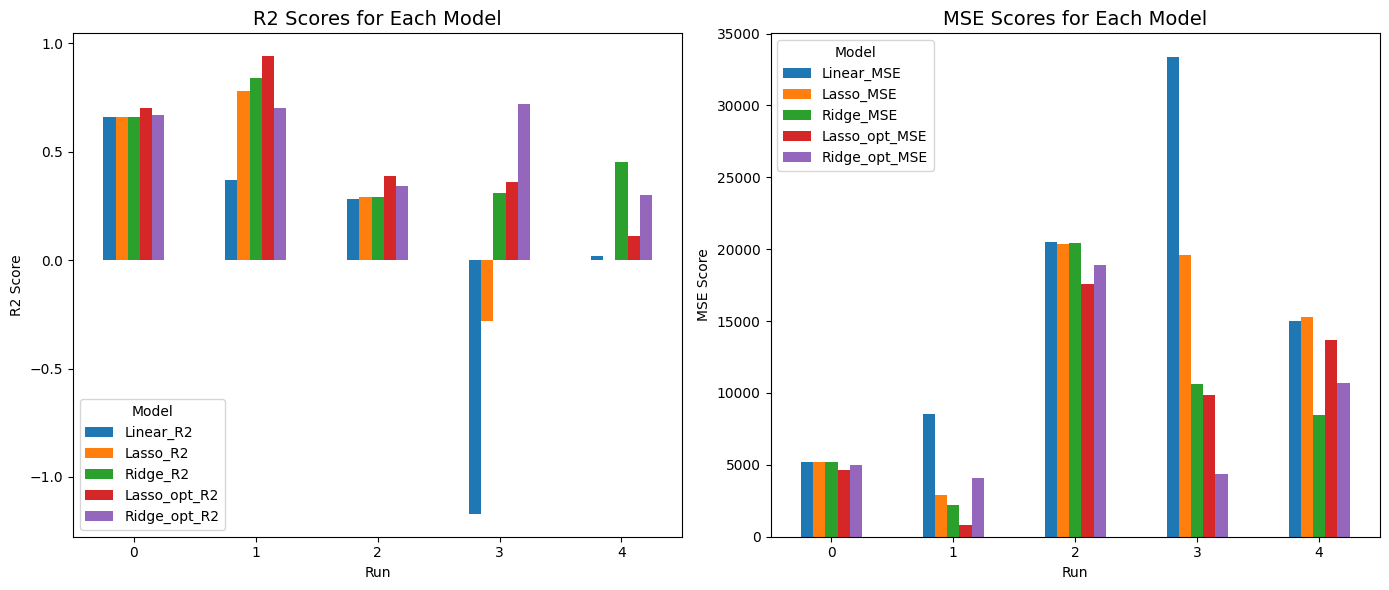

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- PLOT 1: R2 Scores (on ax1) ---
r2_columns = [col for col in df.columns if 'R2' in col]
df[r2_columns].plot(
    kind='bar',
    ax=ax1,
    rot=0
)
ax1.set_title('R2 Scores for Each Model', fontsize=14)
ax1.set_xlabel('Run')
ax1.set_ylabel('R2 Score')
ax1.legend(title='Model', loc='lower left')


# --- PLOT 2: MSE Scores (on ax2) ---
mse_columns = [col for col in df.columns if 'MSE' in col]
df[mse_columns].plot(
    kind='bar',
    ax=ax2,
    rot=0
)
ax2.set_title('MSE Scores for Each Model', fontsize=14)
ax2.set_xlabel('Run')
ax2.set_ylabel('MSE Score')
ax2.legend(title='Model', loc='upper left')

plt.tight_layout()
plt.show()


### Here is a general interpretation of the output:

* The rows of table represent different runs, with different datasets and configurations.
* For each run, you have performance metrics (R-squared and MSE) for several regression models, including Linear Regression, Lasso Regression, and Ridge Regression.
* You also have the corresponding hyperparameter values (alpha) for Lasso and Ridge Regression.
* R-squared is a measure of how well the independent variables explain the variation in the dependent variable. So, higher R2 values indicate a better fit to the data, with 1.0 being a perfect fit.
* MSE measures the average squared difference between the actual and predicted values. Lower MSE values indicate better model performance, with 0 being a perfect fit.


Now based on the results answer the following questions:

### Question 1: Look at the R-squared values:

Compare R2 values across different models to see which one performs best for each run.

*answer here:*

Run 0:





Run 1:





Run 2:





Run 3:





Run 4:



-------------------------

### Question 2: Examine the MSE values:

Compare MSE values across different models to determine which model has the lowest prediction error for each run.

*answer here:*

Run 0:





Run 1:





Run 2:





Run 3:





Run 4:


-------------------

### Question 3: Study the impact of hyperparameter tuning (alpha optimization):

Compare Lasso and Ridge models with both the optimal and initial alpha values for each run. Did all the models meet our expectations with the optimal alpha? If not, what do you believe might be the reasons for the differences in performance?

*answer here:*

Optimal α is generally better than the default α.

Ridge tends to perform more consistently, especially with correlated features.

Lasso may underperform if the true model isn't sparse or if features are correlated.

Differences in performance are often due to α selection, feature scaling, sparsity assumptions, multicollinearity, or noise.

### Tuning Hyperparameters


Hyperparameters are model parameters that are not learned from the data. Instead, they must be determined by the user. We used `GridSearchCV` as a tool for tuning hyperparameters.

In some cases, which hyperparameters to choose are intuitive based on the user's knowledge of their data and how the chosen models function. In other cases, it's not immediately clear which hyperparameters should be chosen. When this is the case, tools like `GridSearchCV` can help us determine optimal hyperparameters through repeated cross validation - thats what the 'CV' stands for in `GridSearchCV` - **C**ross-**V**alidation.

In the case of our regression models, the hyperparameter in question is alpha/lambda.

Here's how `GridSearchCV` works:

1. We create an array of all values we want to try for the hyperparameter in question.
  * We created this array at **Line 30** of the `regression_models` function. (i.e. `alphas = np.logspace(-3, 3, 300)`)
2. It trains a model with each hyperparameter and evaluates each model using cross-validation.
3. Cross-validation works by splitting the training data into several subsets. This is done similarly to how we original split our data into training and testing subsets:
  * It takes the training data and further splits it into training and testing data.
  * It trains a model on the new training subset and evaluates it on the new testing subset.
  * It then goes back to the original training dataset and splits it differently.
  * Cross-validation will repeat this process for a set number of iterations.
  * In our case, we told it to repeat 5 times (**Lines 45 & 49** in the regression_models function using "cv=5").
4. GridSearchCV stores the performance of each alpha value. Once all iterations are complete, it applies what it has determined to be the optimal alpha values.

Below is a basic visual example of how cross-validation works.

Imagine that all plots along the line comprise the original training dataset.

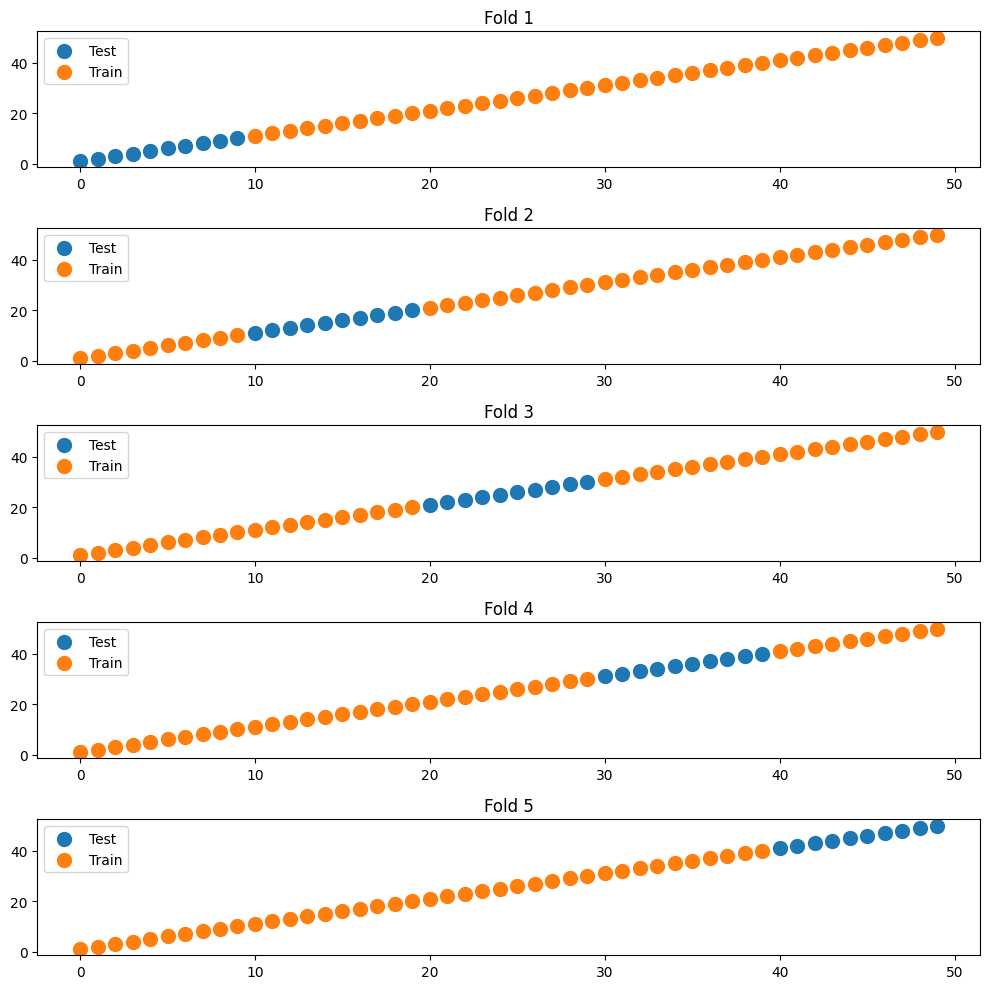

In [ ]:
# Create data
data = np.array([i for i in range(1, 51)])

# Number of folds
k = 5

# Size of each fold
size = len(data)//k

fig, ax = plt.subplots(k, figsize=(10, 10))

# Iterate over each fold
for i in range(k):
    # Create train/test masks
    test_mask = np.zeros(len(data), dtype=bool)
    test_mask[i*size:(i+1)*size] = True
    train_mask = ~test_mask

    # Plot the data
    ax[i].scatter(np.where(test_mask)[0], data[test_mask], label='Test', s=100)
    ax[i].scatter(np.where(train_mask)[0], data[train_mask], label='Train', s=100)
    ax[i].set_title(f'Fold {i+1}')
    ax[i].legend()

# Show the plot
plt.tight_layout()
plt.show()

Now let's look at another example of Lasso and Ridge resgression:

## Example 2: Iris Dataset

 In this new example we used a classic dataset in machine learning called "Iris dataset". The Iris dataset contains 150 samples of iris flowers, each from one of three species: setosa, versicolor, and virginica. The dataset includes four features for each sample: sepal length, sepal width, petal length, and petal width, all measured in centimeters.

The goal of this analysis is to build Lasso and Ridge regression models to predict or classify the iris species based on the provided features.

### Packages

All the packages are the same as in the previous example, except for these two:

- We will use the Iris dataset from `scikit-learn`, loaded using `load_iris()`.
- We will use `StandardScaler` from `sklearn.preprocessing` to standardize the feature variables.

You have already imported all the required packages at the beginning of this chapter, so you do not need to do anything right now

### Standardizing and Splitting Data

First, we load the Iris dataset using `load_iris()` and assign the features to X and the target variable to y.

In [ ]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

Then, we standardize the feature variables X using the `StandardScaler` to ensure that they have a mean of 0 and a standard deviation of 1.
The main reason that we do standardization, is that these regularization methods are sensitive to the scale of the features. So, standardizing ensures that all features contribute to the model on the same scale, preventing any single feature from dominating the regularization process.

In [ ]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Next, we split the data into training and testing sets. The training set (80% of the data) is used to train the models, and the testing set (20%) is used to evaluate the models.

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

### Training Regression Models (L1 and L2)

First, we train a Lasso regression model with an initial alpha of 0.1. The `max_iter` parameter controls the maximum number of iterations during training.

Then, we perform a grid search to find the optimal alpha value for the Lasso model using cross-validation. This helps us choose the best regularization strength for the Lasso model.

Finally, We create a new Lasso model with the optimal alpha found in the previous step and train it on the training data.

In [ ]:
# Train a Lasso regression model with an initial alpha=0.1
lasso = Lasso(alpha=0.1, max_iter=10000)
lasso.fit(X_train, y_train)

# Perform grid search to find the optimal alpha for the Lasso model
alphas = np.logspace(-3, 3, 300)
lasso_cv = GridSearchCV(Lasso(max_iter=10000), param_grid={'alpha': alphas}, scoring='neg_mean_squared_error', cv=5)
lasso_cv.fit(X_train, y_train)

# Train the Lasso model with the optimal alpha
lasso_opt = Lasso(alpha=lasso_cv.best_params_['alpha'], max_iter=10000)
lasso_opt.fit(X_train, y_train)


Lasso(alpha=np.float64(0.001), max_iter=10000)

We use the trained Lasso model to make predictions on the test data and evaluate its performance. We calculate the Mean Squared Error (MSE) and R-squared (R2) for the Lasso model to assess its predictive accuracy.

In [ ]:
# Evaluate the Lasso model on the test data
lasso_predictions = lasso_opt.predict(X_test)

# Calculate the Mean Squared Error and R-squared for Lasso
lasso_mse = mean_squared_error(y_test, lasso_predictions)
lasso_r2 = r2_score(y_test, lasso_predictions)

And now we follow the similar structure for Ridge regression:

In [ ]:
# Train a Ridge regression model with an initial alpha=0.1
ridge = Ridge(alpha=0.1, max_iter=10000)
ridge.fit(X_train, y_train)

# Perform grid search to find the optimal alpha for the Ridge model
alphas = np.logspace(-3, 3, 300)
ridge_cv = GridSearchCV(Ridge(max_iter=10000), param_grid={'alpha': alphas}, scoring='neg_mean_squared_error', cv=5)
ridge_cv.fit(X_train, y_train)

# Train the Ridge model with the optimal alpha
ridge_opt = Ridge(alpha=ridge_cv.best_params_['alpha'], max_iter=10000)
ridge_opt.fit(X_train, y_train)

Ridge(alpha=np.float64(1.7012542798525891), max_iter=10000)

In [ ]:
# Evaluate the Ridge model on the test data
ridge_predictions = ridge_opt.predict(X_test)

# Calculate the Mean Squared Error and R-squared for Ridge
ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

### Comparing Models

Now, let's compare the performance of the two models.

First, we will print the calculated Mean Squared Error and R-squared values for both the Lasso and Ridge models to compare their performance.

You should now be able to compare the models' performance using these two metrics.

In [ ]:
# Print the MSE and R-squared for both Lasso and Ridge models
print("Lasso Regression - MSE:", lasso_mse)
print("Lasso Regression - R-squared:", lasso_r2)
print("Ridge Regression - MSE:", ridge_mse)
print("Ridge Regression - R-squared:", ridge_r2)

Lasso Regression - MSE: 0.03701314050792768
Lasso Regression - R-squared: 0.9470400215307871
Ridge Regression - MSE: 0.03754038554872744
Ridge Regression - R-squared: 0.9462856168619163


And then, let's create a side-by-side bar chart to visualize the feature coefficients for both the Lasso and Ridge models, making it easier to understand the impact of each feature on the models.

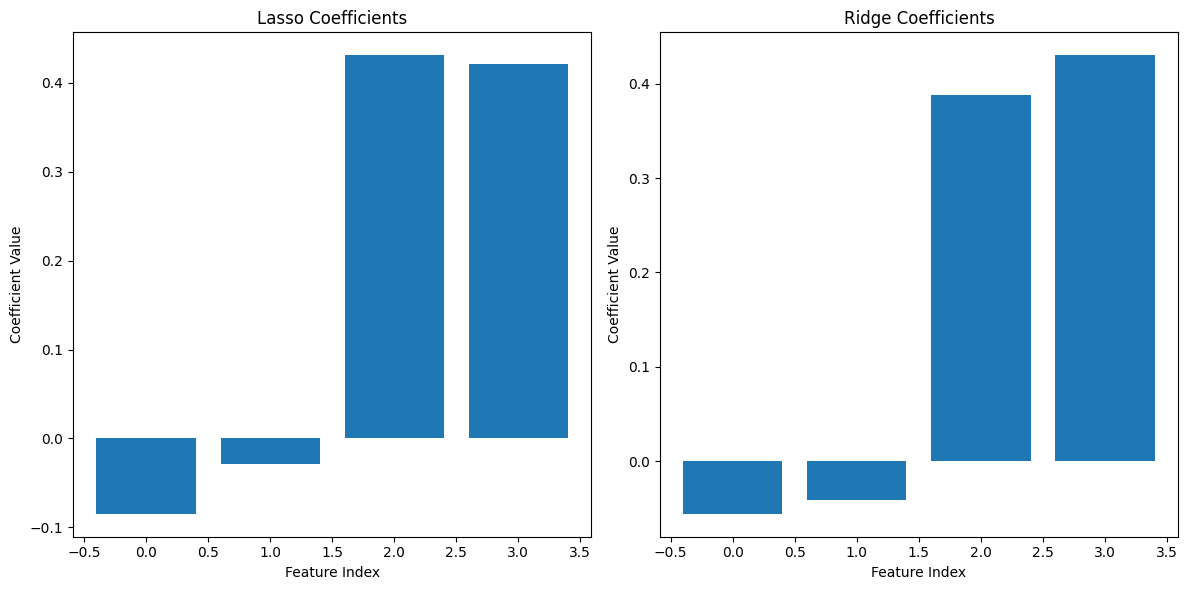

In [ ]:
# Visualize feature coefficients for Lasso and Ridge models
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.bar(range(len(lasso_opt.coef_)), lasso_opt.coef_)
plt.title("Lasso Coefficients")
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.subplot(122)
plt.bar(range(len(ridge_opt.coef_)), ridge_opt.coef_)
plt.title("Ridge Coefficients")
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.tight_layout()
plt.show()

Also to provide better insights into the importance of each feature in the regression models, we can print the coefficients of these two models:

In [ ]:
# Print coefficients for Lasso model
print("Lasso Coefficients:")
print(lasso_opt.coef_)

# Print coefficients for Ridge model
print("\nRidge Coefficients:")
print(ridge_opt.coef_)

Lasso Coefficients:
[-0.0847721  -0.02915445  0.43102257  0.42158412]

Ridge Coefficients:
[-0.05587174 -0.04157637  0.3876334   0.43020692]


In linear regression, understanding the importance of feature coefficients is essential to interpret how each feature affects the model's predictions.

The coefficients represent the strength and direction of the relationship between a feature and the target variable. When a feature coefficient is zero, it implies that the corresponding feature is not considered relevant for the model's prediction.

So, by examining and comparing coefficients, you can gain insights into the role and importance of each feature in your regression model. Obviously, larger coefficients (absolute value) typically indicate greater importance, as they have a stronger impact on the model's predictions. Additionally, you can gain insight into the model complexity and, in the case of Lasso regression, the number of features that are included in the model.

# Additional Questions

#### Question 1 — Effect of Regularization Strength (α)

Goal:
Investigate how changing the regularization parameter α (lambda) affects Ridge and Lasso.
As α increases → coefficients shrink more → simpler but less flexible model.

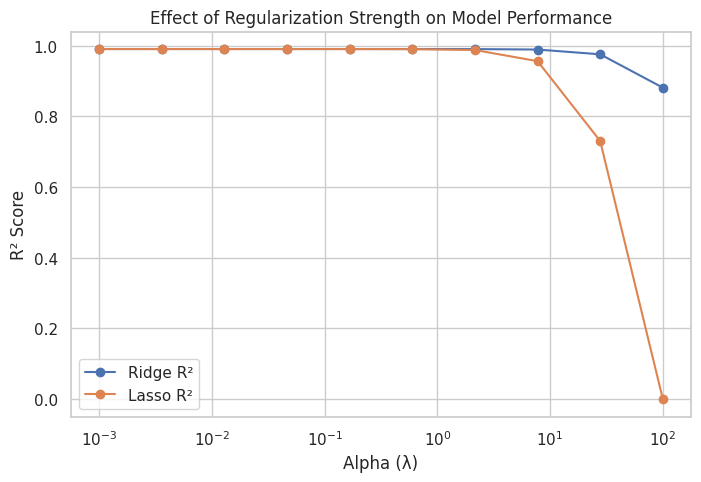

In [ ]:
# Exercise 2 — Effect of α on Ridge and Lasso
from sklearn.linear_model import Ridge, Lasso

alphas = np.logspace(-3, 2, 10)
ridge_scores, lasso_scores = [], []

for a in alphas:
    ridge = Ridge(alpha=a).fit(X_scaled, y)
    lasso = Lasso(alpha=a, max_iter=10000).fit(X_scaled, y)
    ridge_scores.append(ridge.score(X_scaled, y))
    lasso_scores.append(lasso.score(X_scaled, y))

plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_scores, '-o', label="Ridge R²")
plt.plot(alphas, lasso_scores, '-o', label="Lasso R²")
plt.xscale('log')
plt.xlabel("Alpha (λ)")
plt.ylabel("R² Score")
plt.title("Effect of Regularization Strength on Model Performance")
plt.legend()
plt.show()


#### Question 2 - Visualizing Bias-Variance Tradeoff

Goal:
Explore how increasing regularization (α) changes bias and variance.
You'll measure both training and validation errors for different α values.

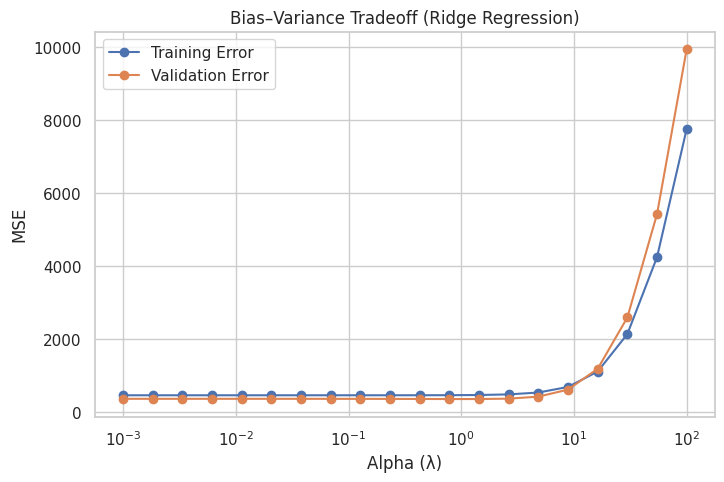

In [ ]:
# Generate a noisy dataset
X, y = make_regression(n_samples=150, n_features=10, noise=20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

alphas = np.logspace(-3, 2, 20)
train_mse, val_mse = [], []

for a in alphas:
    ridge = Ridge(alpha=a).fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, ridge.predict(X_train)))
    val_mse.append(mean_squared_error(y_val, ridge.predict(X_val)))

plt.figure(figsize=(8,5))
plt.plot(alphas, train_mse, label="Training Error", marker='o')
plt.plot(alphas, val_mse, label="Validation Error", marker='o')
plt.xscale("log")
plt.xlabel("Alpha (λ)")
plt.ylabel("MSE")
plt.title("Bias–Variance Tradeoff (Ridge Regression)")
plt.legend()
plt.show()


To select the best model, you should choose the value of Alpha ($\lambda$) that corresponds to the lowest point of the Validation Error (Orange Line).Based on the graph, the minimum validation error occurs around $\alpha = 10^{0}$ or slightly to the right of it. This value balances complexity and regularization to achieve the best possible performance on unseen data.

#### Question 3 - Multicollinearity and Regularization

Goal:
Demonstrate how Ridge stabilizes coefficients when features are highly correlated.

In [ ]:
np.random.seed(42)
X1 = np.random.randn(100)
X2 = X1 * 0.95 + np.random.randn(100)*0.1  # Highly correlated
y = 2*X1 + 2*X2 + np.random.randn(100)*0.5

X = np.column_stack([X1, X2])

ridge = Ridge(alpha=10).fit(X, y)
lasso = Lasso(alpha=0.1).fit(X, y)
ols = LinearRegression().fit(X, y)

print("OLS coefficients:", ols.coef_)
print("Ridge coefficients:", ridge.coef_)
print("Lasso coefficients:", lasso.coef_)


OLS coefficients: [2.17135937 1.93861612]
Ridge coefficients: [1.99182538 1.86978218]
Lasso coefficients: [2.75093005 1.1885836 ]


- OLS gives the “pure” best-fit line. Probably overfits

- Ridge slightly smooths it to avoid overfitting.

- Lasso pushes coefficients toward zero, possibly dropping weaker predictors.